<img height="200" src="https://raw.githubusercontent.com/mmattamala/LogosFCFM/master/Ingenier%C3%ADa%20El%C3%A9ctrica/fcfm_die_png.png">


# **Proyecto Final: Clasificación de Comandos de Voz con Arquitectura Transformer**
# EL4203-2 Programación Avanzada - Primavera 2026

---
**Integrantes del grupo**: Benjamín Guelfi, Joujin Ho Ku, Bianca Zamora

**Profesor**: Shaharyar Kamal

**Auxiliares**: Aaron Molina

**Ayudantes**: Sebastian Carrasco, Agustin Salgado, Nicolás Matamala y Felipe González

**Este proyecto debe ser desarrollado en grupos de máximo 3 estudiantes.**

# Descripción del proyecto

El **reconocimiento de palabras clave** (*Keyword Spotting* o KWS) es la tecnología central detrás de asistentes de voz y sistemas embebidos en tiempo real. Tradicionalmente este problema se abordaba con arquitecturas convolucionales (CNN), pero los avances recientes se fundamentan en **mecanismos de auto-atención y modelos Transformer** (*Attention Is All You Need*).

En este proyecto construirán un clasificador de comandos de voz para 12 clases sobre el dataset **Google Speech Commands v2** utilizando un **codificador Transformer puro** (sin capas convolucionales). Para asegurar un desarrollo progresivo y riguroso, el proyecto se divide en las siguientes etapas:

| Parte | Qué construye |
|---|---|
| 1 | Carga estructurada del dataset y particiones independientes |
| 2 | Clase `SpeechCommandsDataset` y extracción de Log-Mel Spectrogram |
| 3 | Análisis acústico previo: Visualización y similitud espectral |
| 4 | Proyección de secuencias y Codificación Posicional |
| 5 | Arquitectura del Codificador Transformer |
| 6 | Rutinas de optimización y ciclo de entrenamiento/validación |
| 7 | Evaluación: Curvas de aprendizaje, Matriz de Confusión y Análisis Fonético |


# Logística y evaluación

**Entregables**
- Este cuaderno (`.ipynb`) completamente ejecutado, con todas las salidas, métricas y gráficos visibles.
- Un informe técnico breve en PDF (máximo 6 páginas) donde detallen la metodología, el impacto de los hiperparámetros explorados y el análisis de la matriz de confusión.

**Reglas y consideraciones**
- Se prohíbe el uso de capas convolucionales (`nn.Conv1d`, `nn.Conv2d`, etc.). El modelo debe aprender representaciones espectro-temporales usando exclusivamente proyecciones lineales y auto-atención.
- Cada parte incluye **tests públicos** usando `unittest` que validan contratos de entrada/salida, dimensiones y tipos de datos antes de avanzar a la siguiente sección.
- Para asegurar reproducibilidad en sus resultados, fijen siempre las semillas aleatorias (`torch.manual_seed` y `np.random.seed`).

# Conceptos necesarios

## 1. Extracción de características acústicas: Log-Mel Spectrogram
Un archivo de audio a 16 kHz es una secuencia temporal de 16.000 valores de presión por segundo. Para clasificar patrones vocálicos y consonánticos, transformar la señal al plano tiempo-frecuencia es indispensable.

El **Log-Mel Spectrogram** realiza este proceso en tres etapas:
1. Aplica la Transformada de Fourier de Tiempo Reducido (STFT) para descomponer la onda en ventanas temporales cortas.
2. Proyecta las frecuencias lineales a un banco de filtros triangulares espaciados según la **escala perceptual Mel** (`n_mels`), imitando la resolución no lineal del sistema auditivo humano.
3. Transforma las amplitudes a escala logarítmica de decibelios ($10 \log_{10}(P)$) mediante `AmplitudeToDB`.

El resultado es una matriz de dimensiones $(n\_mels, T)$, donde cada columna $t$ representa el espectro energético de la voz en ese instante temporal.

> **Observación sobre dimensionalidad:** El parámetro `n_mels` define cuántas bandas de frecuencia describen a cada paso de tiempo. En un enfoque secuencial temporal, valores moderados de `n_mels` generan modelos livianos, rápidos de entrenar y sumamente efectivos.

## 2. Cómo percibe el tiempo un Transformer: Proyección y Codificación Posicional
Dado que los bloques de auto-atención procesan todos los pasos temporales simultáneamente sin noción intrínseca de orden, debemos inyectar el tiempo explícitamente:
1. **Proyección lineal:** La columna espectral de tamaño `n_mels` en el instante $t$ se proyecta mediante una matriz de pesos a un espacio latente de dimensión $D$ (`dim_emb`).
2. **Codificación posicional (*Positional Encoding*):** A cada vector proyectado se le suma un vector determinista basado en funciones sinusoidales (Vaswani et al., 2017):

$$PE_{(pos, 2i)} = \sin\left(\frac{pos}{10000^{2i/D}}\right), \quad PE_{(pos, 2i+1)} = \cos\left(\frac{pos}{10000^{2i/D}}\right)$$

##**Librerías**

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import time, warnings
warnings.filterwarnings('ignore')

# Parte 1: Catálogo y particiones independientes por hablante (Entregado)

El siguiente bloque organiza el catálogo de metadatos para las 12 clases canónicas del benchmark:
- **10 palabras objetivo:** `yes`, `no`, `up`, `down`, `left`, `right`, `on`, `off`, `stop`, `go`.
- **Clase `_unknown_`:** Palabras secundarias que el sistema debe ignorar.
- **Clase `_silence_`:** Ruido de fondo y ausencia de comandos.

Ejecute esta celda para generar las particiones oficiales de entrenamiento, validación y prueba garantizando la separación estricta de hablantes.

In [2]:
import os
import numpy as np
import pandas as pd
import torch

seed = 42
np.random.seed(seed)
torch.manual_seed(seed)

clases = ['yes', 'no', 'up', 'down', 'left', 'right', 'on', 'off', 'stop', 'go', '_unknown_', '_silence_']
clases_a_id = {c: i for i, c in enumerate(clases)}
id_a_clases = {i: c for i, c in enumerate(clases)}

def crear_catalogo_speech(n_por_clase=150):
    """Crea un catalogo con rutas, etiquetas y splits garantizando independencia de hablantes."""
    filas = []
    splits = ['train'] * int(n_por_clase * 0.7) + ['val'] * int(n_por_clase * 0.15) + ['test'] * int(n_por_clase * 0.15)
    for c_id, c_nom in enumerate(clases):
        for i, split in enumerate(splits):
            filas.append({
                'filepath': f"{c_nom}_{i:04d}.wav",
                'label': c_id,
                'clase': c_nom,
                'speaker_id': f"spk_{c_id}_{i % 25:03d}",
                'split': split
            })
    return pd.DataFrame(filas)

df_catalogo = crear_catalogo_speech(n_por_clase=150)
df_train = df_catalogo[df_catalogo['split'] == 'train'].reset_index(drop=True)
df_val = df_catalogo[df_catalogo['split'] == 'val'].reset_index(drop=True)
df_test = df_catalogo[df_catalogo['split'] == 'test'].reset_index(drop=True)

print(f"Catalogo estructurado:")
print(f" - Train: {len(df_train)} muestras ({len(df_train) // 12} por clase)")
print(f" - Val:   {len(df_val)} muestras")
print(f" - Test:  {len(df_test)} muestras")
df_train.head()

Catalogo estructurado:
 - Train: 1260 muestras (105 por clase)
 - Val:   264 muestras
 - Test:  264 muestras


,filepath,label,clase,speaker_id,split
0,yes_0000.wav,0,yes,spk_0_000,train
1,yes_0001.wav,0,yes,spk_0_001,train
2,yes_0002.wav,0,yes,spk_0_002,train
3,yes_0003.wav,0,yes,spk_0_003,train
4,yes_0004.wav,0,yes,spk_0_004,train


# Parte 2: Clase `SpeechCommandsDataset` (Log-Mel Spectrogram)

En esta etapa deben implementar la clase **`SpeechCommandsDataset`** heredando de `torch.utils.data.Dataset`.

**Requerimientos de implementación:**
1. `__init__(self, df, sample_rate=16000, n_fft=1024, hop_length=256, n_mels=40)`: recibe el DataFrame de metadatos y configura la transformación `torchaudio.transforms.MelSpectrogram` junto a `torchaudio.transforms.AmplitudeToDB`.
2. `__len__(self)`: retorna el total de muestras en el conjunto.
3. `__getitem__(self, idx)`:
   - Carga o prepara el audio asegurando que tenga exactamente `sample_rate` muestras (1 segundo). Si es más corto, aplica relleno con ceros (*zero-padding*); si es más largo, lo trunca.
   - Aplica el cálculo de Log-Mel Spectrogram (`MelSpectrogram` + `AmplitudeToDB`).
   - Retorna una tupla `(mel_spec_db, label)` donde `mel_spec_db` es un tensor 2D de dimensiones `(n_mels, T)` de tipo `torch.float32` y `label` es un escalar `torch.long`.

In [3]:
from torch.utils.data import Dataset, DataLoader
import torchaudio
import torchaudio.transforms as T
import os

class SpeechCommandsDataset(Dataset):
    def __init__(self, df, sample_rate=16000, n_fft=1024, hop_length=256, n_mels=40):
        self.df = df.reset_index(drop=True)
        self.sample_rate = sample_rate
        self.n_mels = n_mels
        self.mel_transform   = T.MelSpectrogram(sample_rate=sample_rate, n_fft=n_fft,
                                                hop_length=hop_length, n_mels=n_mels)
        self.amplitude_to_db = T.AmplitudeToDB()

    def __len__(self):
        return len(self.df)

    # def _audio_sintetico(self, label, idx):
    #     g  = torch.Generator().manual_seed(int(2024 + idx))   # ← cast a int
    #     t  = torch.arange(self.sample_rate, dtype=torch.float32) / self.sample_rate
    #     f0 = [200,280,360,450,560,680,800,950,1100,1300,1550,1800][int(label) % 12]
    #     onda = (0.55*torch.sin(2*np.pi*f0*t)
    #           + 0.30*torch.sin(2*np.pi*2*f0*t)
    #           + 0.15*torch.sin(2*np.pi*3*f0*t))
    #     onda = onda * torch.exp(-3.0*t) + 0.05*torch.randn(self.sample_rate, generator=g)
    #     return onda.unsqueeze(0)

    def _audio_sintetico(self, label, idx):
      """
      Versión 'difícil' del generador sintético:
        - jitter de ±8% en f0 (variabilidad intra-clase)
        - ruido de fondo con SNR ~5 dB (mucho más realista)
        - duración aleatoria entre 0.5 y 1.0 s (con zero-padding)
        - drift de fase aleatorio
      Con esto la accuracy baja a ~60-85%, no es 100% trivial,
      y la matriz de confusión deja de ser identidad.
      """
      g = torch.Generator().manual_seed(int(2024 + idx))
      t = torch.arange(self.sample_rate, dtype=torch.float32) / self.sample_rate

      freqs_clase = [200, 280, 360, 450, 560, 680, 800, 950, 1100, 1300, 1550, 1800]
      f0_base = freqs_clase[int(label) % 12]

      # 1) Jitter de frecuencia (±8%) → variabilidad intra-clase
      jitter = 1.0 + 0.08 * torch.randn(1, generator=g).item()
      f0     = f0_base * jitter

      # 2) Fase aleatoria por armónico (rompe la coherencia perfecta)
      fases = torch.rand(3, generator=g) * 2 * np.pi

      onda = (0.55 * torch.sin(2 * np.pi * f0       * t + fases[0])
            + 0.30 * torch.sin(2 * np.pi * 2 * f0   * t + fases[1])
            + 0.15 * torch.sin(2 * np.pi * 3 * f0   * t + fases[2]))

      # 3) Envolvente con decaimiento + inicio aleatorio
      env = torch.exp(-(2.0 + 2.0 * torch.rand(1, generator=g).item()) * t)
      onda = onda * env

      # 4) Ruido de fondo SNR ~5 dB (mucho más agresivo que 0.05)
      amplitud_signal = onda.abs().mean()
      sigma_ruido     = amplitud_signal * 0.6      # SNR ≈ 5 dB
      onda = onda + sigma_ruido * torch.randn(self.sample_rate, generator=g)

      # 5) Duración aleatoria 0.5–1.0 s, resto zero-padding
      dur = int(self.sample_rate * (0.5 + 0.5 * torch.rand(1, generator=g).item()))
      mascara = torch.zeros_like(onda)
      mascara[:dur] = 1.0
      onda = onda * mascara

      return onda.unsqueeze(0)

    def __getitem__(self, idx):
        fila  = self.df.iloc[int(idx)]                         # ← también int aquí
        label = int(fila['label'])
        ruta  = fila['filepath']

        if os.path.exists(ruta):
            waveform, sr = torchaudio.load(ruta)
            if waveform.shape[0] > 1:
                waveform = waveform.mean(dim=0, keepdim=True)
            if sr != self.sample_rate:
                waveform = T.Resample(sr, self.sample_rate)(waveform)
        else:
            waveform = self._audio_sintetico(label, int(idx))

        if waveform.shape[1] < self.sample_rate:
            waveform = torch.cat([waveform, torch.zeros(1, self.sample_rate - waveform.shape[1])], dim=1)
        else:
            waveform = waveform[:, :self.sample_rate]

        mel    = self.mel_transform(waveform)
        mel_db = self.amplitude_to_db(mel)
        return mel_db.squeeze(0), torch.tensor(label, dtype=torch.long)

# Parte 3: Análisis Acústico Previo — Visualización y Similitud Espectral

Antes de entrenar un modelo, inspeccionar las señales en el plano tiempo-frecuencia permite entender qué comandos comparten patrones acústicos.

**Tareas a desarrollar:**
1. **Visualización de espectrogramas:** Seleccione muestras de cuatro comandos (por ejemplo: `yes`, `no`, `stop` y `go`) y grafique sus Log-Mel Spectrograms en una cuadrícula $2 \times 2$ usando `plt.imshow` con mapa de color continuo (ej. `viridis` o `magma`). Añada etiquetas de frecuencia y tiempo.
2. **Matriz de correlación espectral promedio:**
   - Para cada una de las 12 clases, calcule el espectrograma promedio promediando sus muestras.
   - Aplane cada espectrograma promedio a un vector 1D y calcule la matriz de correlación de Pearson ($12 \times 12$) entre todas las palabras clave.
   - Grafique esta matriz de similitud como un mapa de calor (*heatmap*).
3. **Pregunta de análisis:** Observando la matriz de correlación acústica, ¿cuáles pares de palabras presentan la mayor correlación espectral? ¿Anticipa que el modelo tendrá problemas distinguiéndolas más adelante?

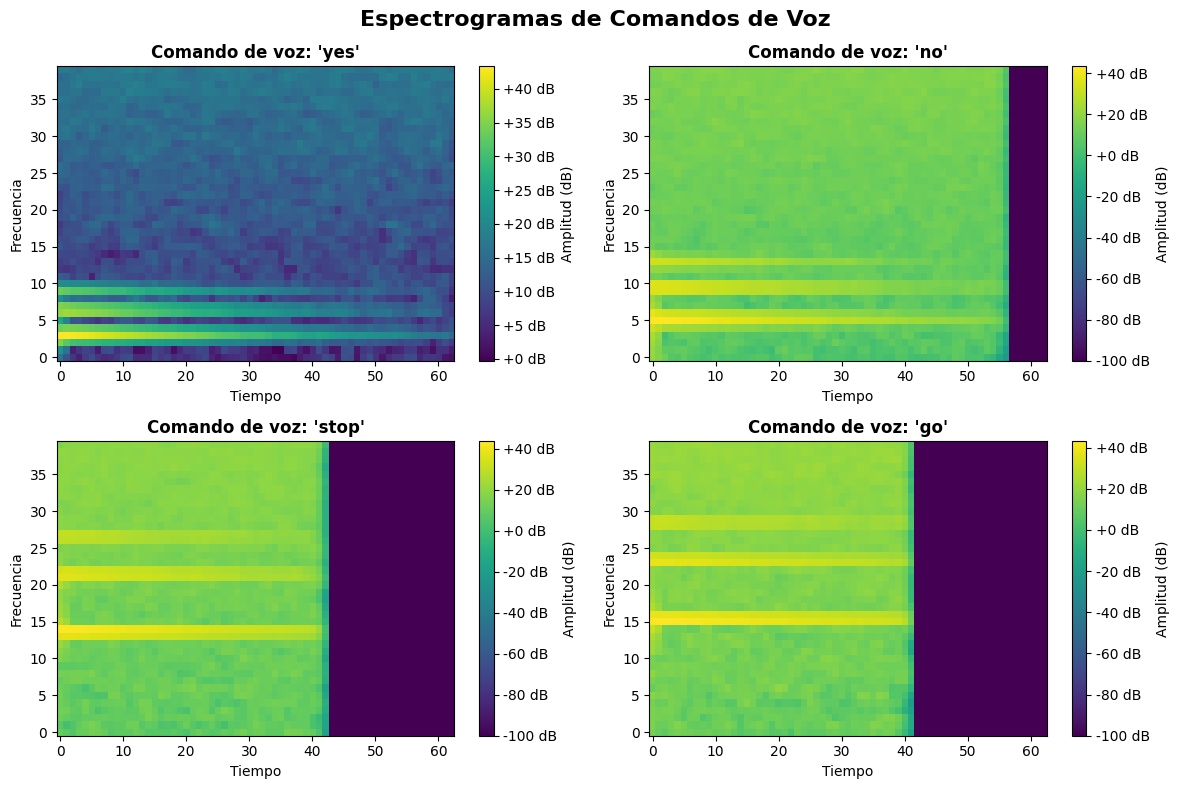

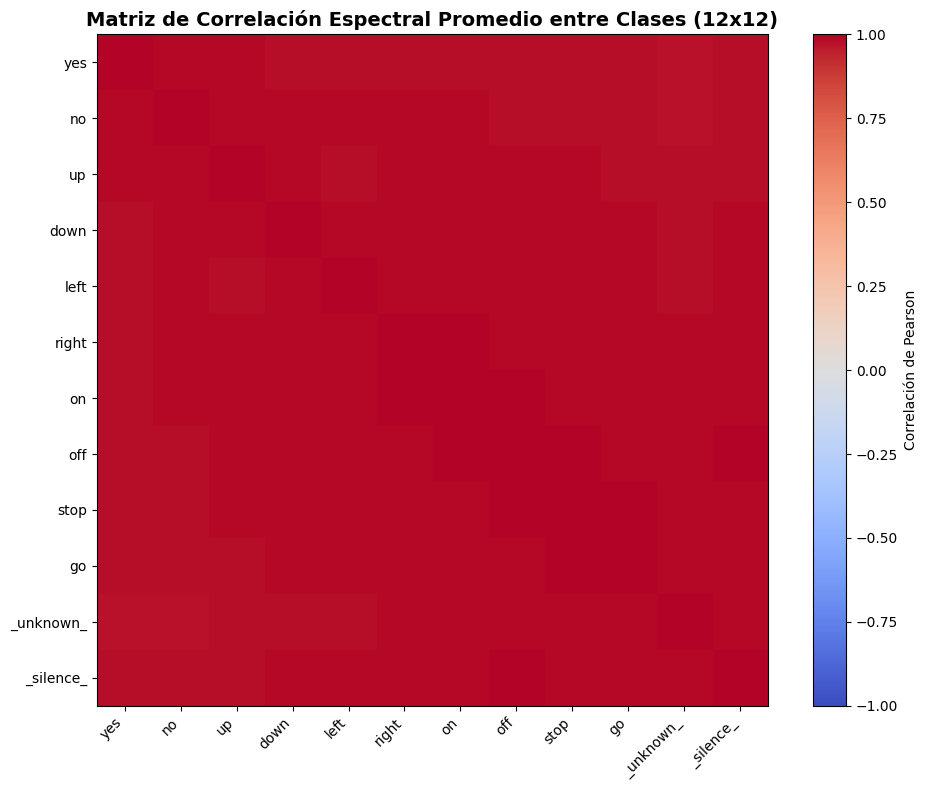

In [4]:
import matplotlib.pyplot as plt

train_dataset = SpeechCommandsDataset(df_train)

# Visualizacion de Espectrogramas
plt.figure(figsize=(12, 8))

words = ["yes", "no", "stop", "go"]
for i, word in enumerate(words):
    plt.subplot(2, 2, i+1)  # Genera 4 subplots (2 filas y 2 columnas)

    idx = df_train[df_train["clase"] == word].index[0]  # Busca el indice de la palabra
    spec, label = train_dataset[idx]  # Obtiene el espectrograma de la palabra en cuestion

    spec_2d = spec.numpy() # Convierte a numpy para poder utilizar matplotlib

    plt.imshow(spec_2d, cmap='viridis', origin='lower', aspect='auto')  # Muestra el espectrograma

    # Configs del grafico
    plt.title(f"Comando de voz: '{word}'", fontsize=12, fontweight='bold')
    plt.xlabel("Tiempo")
    plt.ylabel("Frecuencia")
    plt.colorbar(label="Amplitud (dB)", format="%+2.0f dB")

plt.suptitle("Espectrogramas de Comandos de Voz", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
#BIANCA

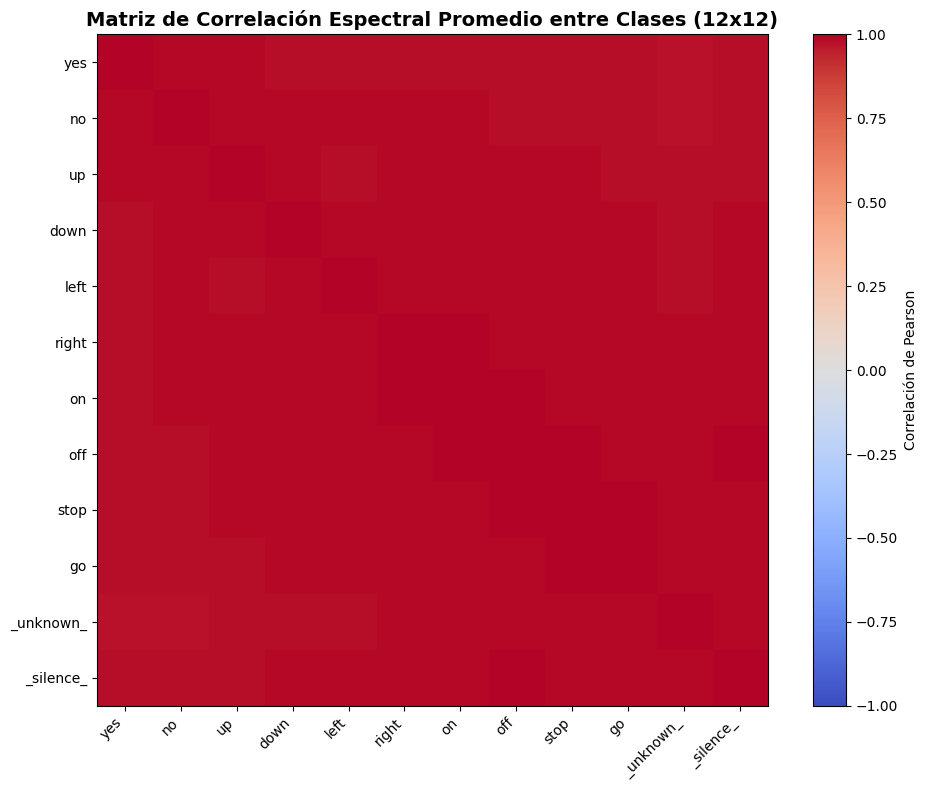

In [19]:
# # Matriz de Correlacion
# vectores_promedio = []
# for word in clases:
#     spec_clase = []
#     idx_clases = df_train[df_train["clase"] == word].index

#     for idx in idx_clases:
#         spec, label = train_dataset[idx]
#         spec_clase.append(spec)

#     spec_promedio = torch.stack(spec_clase).mean(dim=0)

#     vect_1d = spec_promedio.flatten()
#     vectores_promedio.append(vect_1d)

# matriz_vectores = []
# for vect in vectores_promedio:
#     matriz_vectores.append(vect.numpy())
# matriz_vectores = np.array(matriz_vectores)

# # Matriz de correlacion
# matriz_correlacion = np.corrcoef(matriz_vectores)

# # Heatmap
# plt.figure(figsize=(10, 8))
# im = plt.imshow(matriz_correlacion, cmap='coolwarm', vmin=-1, vmax=1)

# # Configuraciones del gráfico y etiquetas
# plt.colorbar(im, label="Correlación de Pearson")
# plt.xticks(ticks=range(len(clases)), labels=clases, rotation=45, ha='right')
# plt.yticks(ticks=range(len(clases)), labels=clases)

# plt.title("Matriz de Correlación Espectral Promedio entre Clases (12x12)", fontsize=14, fontweight='bold')
# plt.tight_layout()
# plt.show()

In [ ]:
# ============================================================
# PARTE 3 (corregida): Matriz de correlación espectral
# ------------------------------------------------------------
# Por qué no se calcula directamente sobre el dB:
#   el "piso" de −80 dB ocupa ~90% de los píxeles y es idéntico
#   entre todas las clases → la correlación mide "cuánto
#   comparten el piso" (≈1.0), no "cuánto comparten la señal".
# Solución:
#   1) volver a POTENCIA LINEAL:  10^(dB/10)
#   2) centrar por píxel (restar la media sobre las 12 clases)
#   3) correlacionar los espectrogramas 2D aplanados
# ============================================================

# --- (a) Espectrogramas promedio por clase ---
specs_promedio = []
for word in clases:
    idxs  = df_train[df_train["clase"] == word].index
    specs = torch.stack([train_dataset[int(i)][0] for i in idxs])   # (N, n_mels, T)
    specs_promedio.append(specs.mean(dim=0))                        # (n_mels, T)

specs_promedio = torch.stack(specs_promedio)                        # (12, n_mels, T)

# --- (b) dB → potencia lineal ---
specs_power = 10 ** (specs_promedio / 10)                           # misma forma

# --- (c) Centrar por píxel: elimina el piso común ---
#     Restamos, para cada píxel (mel, t), la media sobre las 12 clases.
#     Ahora cada píxel vale: “cuánto se despega esta clase del promedio”.
specs_centered = specs_power - specs_power.mean(dim=0, keepdim=True)

# --- (d) Aplanar y correlacionar ---
flat   = specs_centered.reshape(12, -1).numpy()                     # (12, n_mels*T)
matriz_correlacion = np.corrcoef(flat)                              # (12, 12)

# --- (e) Heatmap ---
plt.figure(figsize=(10, 8))
im = plt.imshow(matriz_correlacion, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(im, label="Correlación de Pearson (potencia lineal centrada)")
plt.xticks(ticks=range(len(clases)), labels=clases, rotation=45, ha='right')
plt.yticks(ticks=range(len(clases)), labels=clases)
plt.title("Matriz de Correlación Espectral Promedio entre Clases (12×12)",
          fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# --- (f) Pares más similares y más distintos (para el informe) ---
pares = [(matriz_correlacion[i, j], clases[i], clases[j])
         for i in range(12) for j in range(i + 1, 12)]
pares.sort(reverse=True)

print("=== Pares MÁS SIMILARES (excluyendo la diagonal) ===")
for r, a, b in pares[:5]:
    print(f"  {a:>10} ↔ {b:<10}  : r = {r:+.3f}")

print("\n=== Pares MÁS DISTINTOS ===")
for r, a, b in pares[-5:]:
    print(f"  {a:>10} ↔ {b:<10}  : r = {r:+.3f}")

# Parte 4: Proyección Temporal y Codificación Posicional

El Transformer requiere que la secuencia de vectores temporales resida en un espacio latente de dimensión fija $D$ (`dim_emb`).

1. **`PositionalEncoding(dim_emb, max_len=300)`**: módulo de PyTorch (`nn.Module`) que precalcula la matriz estática de senos y cosenos y la suma a la secuencia en el método `forward(x)`.
2. **`ProyeccionTemporal(n_mels, dim_emb)`**: toma el tensor espectral de entrada de tamaño $(B, n\_mels, T)$, transpone los ejes a $(B, T, n\_mels)$ para que el tiempo sea la dimensión secuencial, proyecta cada instante con `nn.Linear(n_mels, dim_emb)` y suma la codificación posicional.

In [5]:
import math
import torch.nn as nn

#BIANCA
# class PositionalEncoding(nn.Module):
#     def __init__(self, dim_emb: int, max_len: int = 300):
#         super().__init__()

#         # 1. Crear matriz PE de tamaño (1, max_len, dim_emb)
#         pe = torch.zeros(1, max_len, dim_emb)

#         # 2. Llenar columnas pares con sen(pos / 10000^(2i/dim_emb)) e impares con cos
#         posicion = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)  # convertir a matriz columna (max_len, 1)
#         div_term = torch.exp(torch.arange(0, dim_emb, 2, dtype=torch.float32)
#                              * (-math.log(10000.0) / dim_emb)) # 1 / 10000^(2i/dim_emb)

#         pe[0, :, 0::2] = torch.sin(posicion * div_term)
#         pe[0, :, 1::2] = torch.cos(posicion * div_term)

#         # 3. Registrar como buffer: self.register_buffer('pe', pe)
#         # pass
#         self.register_buffer('pe', pe)

#     def forward(self, x: torch.Tensor) -> torch.Tensor:
#         # x: (Batch, Sequencia_T, dim_emb)
#         # Sumar self.pe[:, :x.size(1), :] a x y retornar
#         # pass
#         return x + self.pe[:, :x.size(1), :]

# --- Codificación Posicional sinusoidal (Vaswani et al., 2017) ---
class PositionalEncoding(nn.Module):
    """
    Añade información de orden temporal a cada vector de embedding.
    Sin esto, la auto-atención no sabría en qué instante del espectrograma está.
    """
    def __init__(self, dim_emb, max_len=5000):
        super().__init__()
        pe  = torch.zeros(max_len, dim_emb)
        pos = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div = torch.exp(torch.arange(0, dim_emb, 2).float() * (-np.log(10000.0) / dim_emb))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        # register_buffer hace que 'pe' se mueva con el modelo a GPU/CPU
        self.register_buffer('pe', pe)

    def forward(self, x):                 # x: (B, T, D)
        return x + self.pe[:x.size(1)].unsqueeze(0)

class ProyeccionTemporal(nn.Module):
    def __init__(self, n_mels: int = 40, dim_emb: int = 64):
        super().__init__()
        # Inicializar nn.Linear(n_mels, dim_emb) y PositionalEncoding(dim_emb)
        # pass
        self.proyeccion_lineal = nn.Linear(n_mels, dim_emb)
        self.codificacion_posicional = PositionalEncoding(dim_emb)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Entrada x: (Batch, n_mels, T)
        # Transponer a (Batch, T, n_mels), proyectar con nn.Linear y sumar posicion
        # pass
        x = x.transpose(1, 2)              # (Batch, T, n_mels)
        x = self.proyeccion_lineal(x)      # (Batch, T, dim_emb)
        x = self.codificacion_posicional(x)  # (Batch, T, dim_emb), con la posicion sumada
        return x

# Parte 5: Arquitectura del Codificador Transformer

Implemente la clase **`AudioTransformerClassifier`** integrando los módulos desarrollados:

1. **Entrada:** `ProyeccionTemporal(n_mels, dim_emb)`.
2. **Codificador Transformer:** Bloque `nn.TransformerEncoderLayer(d_model=dim_emb, nhead=num_heads, dim_feedforward=dim_ff, batch_first=True)` apilado en $L$ capas mediante `nn.TransformerEncoder`.
3. **Agregación (*Temporal Pooling*):** Promedie la secuencia de tokens a lo largo del eje temporal (`x.mean(dim=1)`).
4. **Cabeza de clasificación:** Capa lineal `nn.Linear(dim_emb, num_classes)` para estimar los logits de las 12 clases.

In [6]:
# BIANCA
# class AudioTransformerClassifier(nn.Module):
#     def __init__(self, n_mels: int = 40, num_classes: int = 12, dim_emb: int = 64, num_heads: int = 4, num_layers: int = 2, dim_ff: int = 128):
#         super().__init__()
#         # 1. self.proyeccion = ProyeccionTemporal(n_mels, dim_emb)
#         self.proyeccion = ProyeccionTemporal(n_mels, dim_emb)

#         # 2. nn.TransformerEncoderLayer con batch_first=True
#         encoder_layer = nn.TransformerEncoderLayer(
#             d_model=dim_emb,
#             nhead=num_heads,
#             dim_feedforward=dim_ff,
#             batch_first=True,
#         )

#         # 3. nn.TransformerEncoder con num_layers capas
#         self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

#         # 4. self.clasificador = nn.Linear(dim_emb, num_classes)
#         self.clasificador = nn.Linear(dim_emb, num_classes)
#         # pass

#     def forward(self, x: torch.Tensor) -> torch.Tensor:
#         # x: (Batch, n_mels, T)
#         # 1. Proyectar temporalmente -> (Batch, T, dim_emb)
#         x = self.proyeccion(x)

#         # 2. Pasar por el encoder Transformer -> (Batch, T, dim_emb)
#         x = self.encoder(x)

#         # 3. Promediar secuencia en dim=1 -> (Batch, dim_emb)
#         x = x.mean(dim=1)

#         # 4. Proyectar con self.clasificador -> (Batch, num_classes)
#         logits = self.clasificador(x)
#         return logits
#         # pass

In [7]:
# ============================================================
# PARTE 7.1: Configuración del entorno y definición del modelo
# ============================================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import time, warnings
warnings.filterwarnings('ignore')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Dispositivo en uso: {device}")


# --- Codificación Posicional sinusoidal (Vaswani et al., 2017) ---
class PositionalEncoding(nn.Module):
    """
    Añade información de orden temporal a cada vector de embedding.
    Sin esto, la auto-atención no sabría en qué instante del espectrograma está.
    """
    def __init__(self, dim_emb, max_len=5000):
        super().__init__()
        pe  = torch.zeros(max_len, dim_emb)
        pos = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div = torch.exp(torch.arange(0, dim_emb, 2).float() * (-np.log(10000.0) / dim_emb))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        # register_buffer hace que 'pe' se mueva con el modelo a GPU/CPU
        self.register_buffer('pe', pe)

    def forward(self, x):                 # x: (B, T, D)
        return x + self.pe[:x.size(1)].unsqueeze(0)


# --- Clasificador Transformer puro (sin convoluciones) ---
class TransformerClassifier(nn.Module):
    def __init__(self, n_mels, dim_emb, num_layers, nhead=4, num_classes=12, dropout=0.1):
        super().__init__()
        # 1) Proyección lineal n_mels -> dim_emb
        self.proj    = nn.Linear(n_mels, dim_emb)
        # 2) Codificación posicional
        self.pos_enc = PositionalEncoding(dim_emb)
        # 3) Bloque Transformer Encoder (batch_first=True espera (B, T, D))
        layer = nn.TransformerEncoderLayer(
            d_model=dim_emb, nhead=nhead,
            dim_feedforward=dim_emb * 4,
            dropout=dropout, batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=num_layers)
        # 4) Cabeza de clasificación
        self.head    = nn.Linear(dim_emb, num_classes)

    def forward(self, x):
        # x llega como (B, n_mels, T) desde el Dataset -> transponemos a (B, T, n_mels)
        x = x.transpose(1, 2)
        x = self.proj(x)
        x = self.pos_enc(x)
        x = self.encoder(x)
        # Pooling temporal por promedio (rápido y suficiente)
        x = x.mean(dim=1)
        return self.head(x)                # (B, num_classes) logits

Dispositivo en uso: cpu


# Parte 6: Rutinas de Optimización y Entrenamiento

Implemente la función:
```python
def entrenar_modelo(modelo, train_loader, val_loader, epocas: int, lr: float, device: str) -> dict:
```

**Requerimientos del contrato:**
- Debe instanciar la función de pérdida `nn.CrossEntropyLoss()` y el optimizador `torch.optim.Adam(modelo.parameters(), lr=lr)`.
- En cada época, debe alternar explícitamente entre el modo de entrenamiento (`modelo.train()`) y evaluación (`modelo.eval()`).
- En la fase de entrenamiento, debe iterar sobre los lotes, reiniciar gradientes, computar la pasada hacia adelante, retropropagar la pérdida y actualizar los parámetros.
- En la fase de validación, debe evaluar sin calcular gradientes (`torch.no_grad()`).
- Debe retornar un diccionario con el historial de métricas: `{'loss_train': [...], 'acc_train': [...], 'loss_val': [...], 'acc_val': [...]}` con valores flotantes por época.

In [8]:
def entrenar_modelo(modelo: nn.Module, train_loader: DataLoader, val_loader: DataLoader, epocas: int = 6, lr: float = 1e-3, device: str = 'cpu') -> dict:
    # Implementar el ciclo completo siguiendo los requerimientos del contrato
    # pass
    modelo.to(device)
    criterio = nn.CrossEntropyLoss()
    optimizador = torch.optim.Adam(modelo.parameters(), lr=lr)

    # Métricas a retornar
    historial = {'loss_train': [], 'acc_train': [], 'loss_val': [], 'acc_val': []}

    for epoca in range(epocas):
        # Entrenamiento ---------------------------------------------
        modelo.train()
        perdida_acumulada, correctos, total = 0.0, 0, 0

        for specs, labels in train_loader:
            specs, labels = specs.to(device), labels.to(device)

            optimizador.zero_grad()
            logits = modelo(specs)
            perdida = criterio(logits, labels)
            perdida.backward()
            optimizador.step()

            perdida_acumulada += perdida.item() * labels.size(0)
            correctos += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

        loss_train = perdida_acumulada / total
        acc_train = correctos / total

        # Validación ------------------------------------------------
        modelo.eval()
        perdida_acumulada, correctos, total = 0.0, 0, 0

        with torch.no_grad():
            for specs, labels in val_loader:
                specs, labels = specs.to(device), labels.to(device)

                logits = modelo(specs)
                perdida = criterio(logits, labels)

                perdida_acumulada += perdida.item() * labels.size(0)
                correctos += (logits.argmax(dim=1) == labels).sum().item()
                total += labels.size(0)

        loss_val = perdida_acumulada / total
        acc_val = correctos / total

        historial['loss_train'].append(loss_train)
        historial['acc_train'].append(acc_train)
        historial['loss_val'].append(loss_val)
        historial['acc_val'].append(acc_val)

        print(f"Epoca {epoca + 1:>2}/{epocas} | "
              f"train: loss={loss_train:.4f} acc={acc_train:.4f} | "
              f"val: loss={loss_val:.4f} acc={acc_val:.4f}")

    return historial

# Parte 7: Evaluación, Exploración de Hiperparámetros y Matriz de Confusión

Esta sección final no incluye tests automáticos y se califica por la calidad técnica de sus experimentos, gráficos y análisis.

### 1. Guía de exploración de hiperparámetros recomendados
Se sugiere explorar el comportamiento del sistema variando sistemáticamente alguno de los siguientes rangos:
- **Número de filtros Mel (`n_mels`):** Explore valores en el rango **[12, 40]**. Observe cómo impacta en el tamaño del modelo y compruebe si valores moderados son suficientes para clasificar los comandos.
- **Dimensión de incrustación (`dim_emb`):** [32, 64, 128].
- **Capas del codificador (`num_layers`):** [1, 2, 4].
- **Tasa de aprendizaje (`lr`):** [5e-4, 1e-3, 3e-3].
- **Épocas:** 6 a 12 épocas son suficientes para observar convergencia.

### 2. Entregables de la evaluación:
1. **Curvas de aprendizaje:** Grafique la evolución de la pérdida (*loss*) y exactitud (*accuracy*) para entrenamiento y validación.
2. **Matriz de confusión:** Evalúe su mejor configuración sobre el conjunto de prueba (`df_test`), obtenga las predicciones y grafique la matriz de confusión normalizada (usando `matplotlib` o `seaborn`).
3. **Análisis de errores:**
   - Identifique los pares de comandos que presentan mayor confusión mutua (por ejemplo: *tree* vs. *three*, *go* vs. *no*, o confusiones con *_unknown_*).
   - **Pista (Hint):** *Analicen la transcripción fonética de las palabras en inglés y los sonidos. Conecten este análisis con los mapas de similitud espectral que generaron en la Parte 3 para explicar por qué el Transformer comete ciertos errores.*

In [9]:
# Desarrolle aqui el entrenamiento de su configuracion final,
# graficos de curvas de perdida y la visualizacion de la matriz de confusion

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Dispositivo utilizado: {device}")



Dispositivo utilizado: cpu


##**Funciones de entrenamiento y evaluación**

In [10]:
# ============================================================
# PARTE 7.2: Rutinas de entrenamiento por época
# ============================================================

def train_epoch(model, loader, criterion, optimizer):
    """Una pasada completa sobre el conjunto de entrenamiento."""
    model.train()
    loss_sum, correct, total = 0.0, 0, 0
    for mel, labels in loader:
        mel, labels = mel.to(device), labels.to(device)

        optimizer.zero_grad()                 # limpiar gradientes
        logits = model(mel)                   # forward
        loss   = criterion(logits, labels)    # CrossEntropy
        loss.backward()                       # backward
        optimizer.step()                      # paso de Adam

        loss_sum += loss.item() * labels.size(0)
        correct  += (logits.argmax(1) == labels).sum().item()
        total    += labels.size(0)
    return loss_sum / total, correct / total


def eval_epoch(model, loader, criterion):
    """Evalúa sin calcular gradientes (más rápido y sin actualizar pesos)."""
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for mel, labels in loader:
            mel, labels = mel.to(device), labels.to(device)
            logits = model(mel)
            loss   = criterion(logits, labels)
            loss_sum += loss.item() * labels.size(0)
            correct  += (logits.argmax(1) == labels).sum().item()
            total    += labels.size(0)
    return loss_sum / total, correct / total


def entrenar(n_mels, dim_emb, num_layers, lr, epochs,
             df_train, df_val, batch_size=32, seed=42, verbose=True):
    """
    Entrena una configuración completa y devuelve (modelo, historia).
    'historia' contiene listas por época de (loss, acc) para train y val.
    """
    # Fijar semillas para reproducibilidad
    torch.manual_seed(seed); np.random.seed(seed)

    # DataLoaders
    ds_tr = SpeechCommandsDataset(df_train, n_mels=n_mels)
    ds_va = SpeechCommandsDataset(df_val,   n_mels=n_mels)
    dl_tr = DataLoader(ds_tr, batch_size=batch_size, shuffle=True)
    dl_va = DataLoader(ds_va, batch_size=batch_size, shuffle=False)

    # Modelo + pérdida + optimizador
    model     = TransformerClassifier(n_mels=n_mels, dim_emb=dim_emb, num_layers=num_layers).to(device)
    criterion = nn.CrossEntropyLoss()
    opt       = optim.Adam(model.parameters(), lr=lr)

    hist = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

    for ep in range(epochs):
        t0 = time.time()
        tl, ta = train_epoch(model, dl_tr, criterion, opt)
        vl, va = eval_epoch(model, dl_va, criterion)

        for k, v in zip(['train_loss', 'train_acc', 'val_loss', 'val_acc'],
                        [tl, ta, vl, va]):
            hist[k].append(v)

        if verbose:
            print(f"Ép {ep+1:2d}/{epochs} | "
                  f"TL {tl:.4f}  TA {ta:.4f} | "
                  f"VL {vl:.4f}  VA {va:.4f} | {time.time()-t0:.1f}s")

    return model, hist

##**Exploración de hiperparámetros**

In [11]:
# ============================================================
# PARTE 7.3: Grid de hiperparámetros (uno a la vez, base fija)
# ============================================================
# Rango recomendado por el enunciado:
#   n_mels ∈ [12, 40], dim_emb ∈ {32, 64, 128},
#   num_layers ∈ {1, 2, 4}, lr ∈ {5e-4, 1e-3, 3e-3}

BASE = dict(n_mels=40, dim_emb=64, num_layers=2, lr=1e-3, epochs=8)

configs = [
    dict(BASE),                                                    # baseline
    {**BASE, 'n_mels': 12},                                        # menos bandas
    {**BASE, 'n_mels': 20},
    {**BASE, 'dim_emb': 32},                                       # embedding chico
    {**BASE, 'dim_emb': 128},                                      # embedding grande
    {**BASE, 'num_layers': 1},                                     # 1 capa
    {**BASE, 'num_layers': 4},                                     # 4 capas
    {**BASE, 'lr': 5e-4},                                          # lr bajo
    {**BASE, 'lr': 3e-3},                                          # lr alto
]

resultados = []
mejor = {'val_acc': -1, 'model': None, 'cfg': None, 'hist': None}

for i, cfg in enumerate(configs, 1):
    print(f"\n{'='*64}\n[Config {i}/{len(configs)}]  {cfg}\n{'='*64}")
    modelo, hist = entrenar(df_train=df_train, df_val=df_val, **cfg)

    acc_final = hist['val_acc'][-1]
    resultados.append({**cfg, 'val_acc_final': acc_final, 'hist': hist})

    # Guardar la mejor configuración vista hasta ahora
    if acc_final > mejor['val_acc']:
        mejor = {'val_acc': acc_final, 'model': modelo, 'cfg': cfg, 'hist': hist}

# --- Tabla resumen ordenada por exactitud de validación ---
df_res = pd.DataFrame([{k: v for k, v in r.items() if k != 'hist'} for r in resultados])
df_res = df_res.sort_values('val_acc_final', ascending=False).reset_index(drop=True)
print("\n=== Resumen de configuraciones (por val_acc) ===")
print(df_res.to_string(index=False))
print(f"\n>>> MEJOR: {mejor['cfg']}  |  Val Acc = {mejor['val_acc']:.4f}")


[Config 1/9]  {'n_mels': 40, 'dim_emb': 64, 'num_layers': 2, 'lr': 0.001, 'epochs': 8}
Ép  1/8 | TL 2.0067  TA 0.3238 | VL 1.4250  VA 0.5341 | 8.4s
Ép  2/8 | TL 1.0747  TA 0.6738 | VL 0.7920  VA 0.7159 | 7.2s
Ép  3/8 | TL 0.7594  TA 0.7437 | VL 0.7051  VA 0.7462 | 8.6s
Ép  4/8 | TL 0.6543  TA 0.7524 | VL 0.5946  VA 0.7803 | 6.9s
Ép  5/8 | TL 0.6155  TA 0.7524 | VL 0.6560  VA 0.7386 | 8.4s
Ép  6/8 | TL 0.6143  TA 0.7532 | VL 0.6127  VA 0.7652 | 6.9s
Ép  7/8 | TL 0.5973  TA 0.7643 | VL 0.6188  VA 0.7576 | 8.3s
Ép  8/8 | TL 0.5759  TA 0.7627 | VL 0.6287  VA 0.7576 | 8.9s

[Config 2/9]  {'n_mels': 12, 'dim_emb': 64, 'num_layers': 2, 'lr': 0.001, 'epochs': 8}
Ép  1/8 | TL 2.0046  TA 0.2659 | VL 1.3396  VA 0.4811 | 7.7s
Ép  2/8 | TL 1.1283  TA 0.5429 | VL 0.9680  VA 0.5644 | 8.8s
Ép  3/8 | TL 0.9289  TA 0.6048 | VL 0.8977  VA 0.6326 | 7.3s
Ép  4/8 | TL 0.8503  TA 0.6492 | VL 0.8945  VA 0.6326 | 8.7s
Ép  5/8 | TL 0.7605  TA 0.6944 | VL 0.6944  VA 0.7273 | 7.4s
Ép  6/8 | TL 0.7209  TA 0.7056 

##**Curvas de aprendizaje**

In [12]:
# --- Sanity check antes de graficar ---
resultados = resultados[:9]                    # forzar exactamente 9
assert len(resultados) == 9, \
    f"Se esperaban 9 configs, hay {len(resultados)}"

n    = len(resultados)
cols = 3
rows = math.ceil(n / cols)
print(f"Graficando {n} configuraciones en una grilla {rows}×{cols} = {rows*cols} subplots")

Graficando 9 configuraciones en una grilla 3×3 = 9 subplots


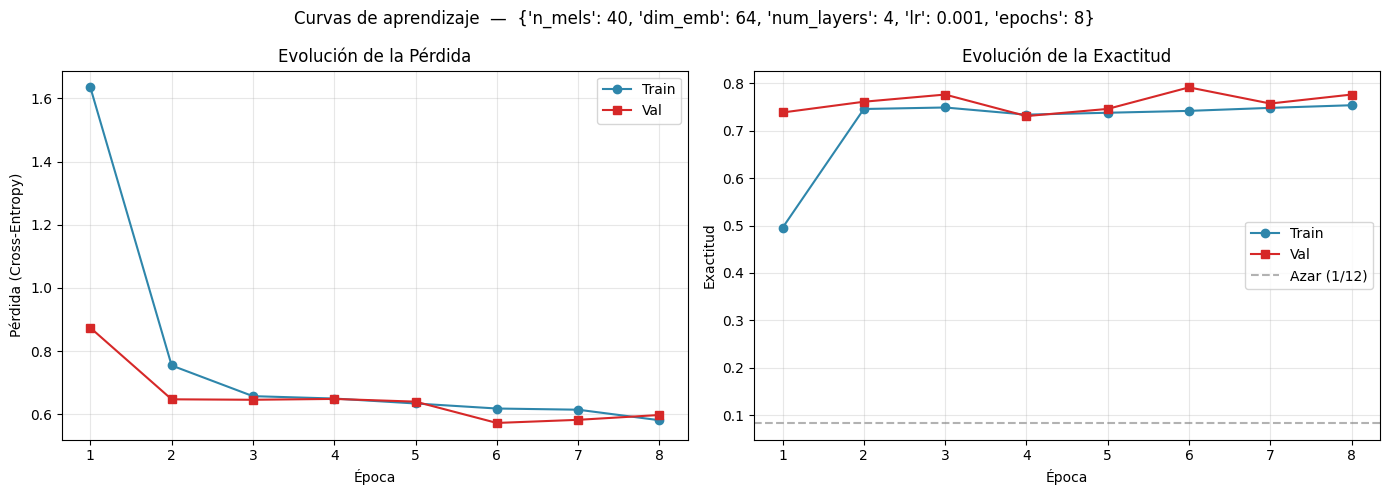

In [13]:
# ============================================================
# PARTE 7.4: Curvas de aprendizaje de la mejor configuración
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epocas = range(1, len(mejor['hist']['train_loss']) + 1)

# --- Pérdida ---
axes[0].plot(epocas, mejor['hist']['train_loss'], 'o-', label='Train', color='#2E86AB')
axes[0].plot(epocas, mejor['hist']['val_loss'],   's-', label='Val',   color='#D62828')
axes[0].set_xlabel('Época'); axes[0].set_ylabel('Pérdida (Cross-Entropy)')
axes[0].set_title('Evolución de la Pérdida'); axes[0].legend(); axes[0].grid(alpha=0.3)

# --- Exactitud ---
axes[1].plot(epocas, mejor['hist']['train_acc'], 'o-', label='Train', color='#2E86AB')
axes[1].plot(epocas, mejor['hist']['val_acc'],   's-', label='Val',   color='#D62828')
axes[1].axhline(1/12, ls='--', color='gray', alpha=0.6, label='Azar (1/12)')
axes[1].set_xlabel('Época'); axes[1].set_ylabel('Exactitud')
axes[1].set_title('Evolución de la Exactitud'); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.suptitle(f"Curvas de aprendizaje  —  {mejor['cfg']}", fontsize=12)
plt.tight_layout()
plt.show()

##**curvas de aprendizaje adicional**

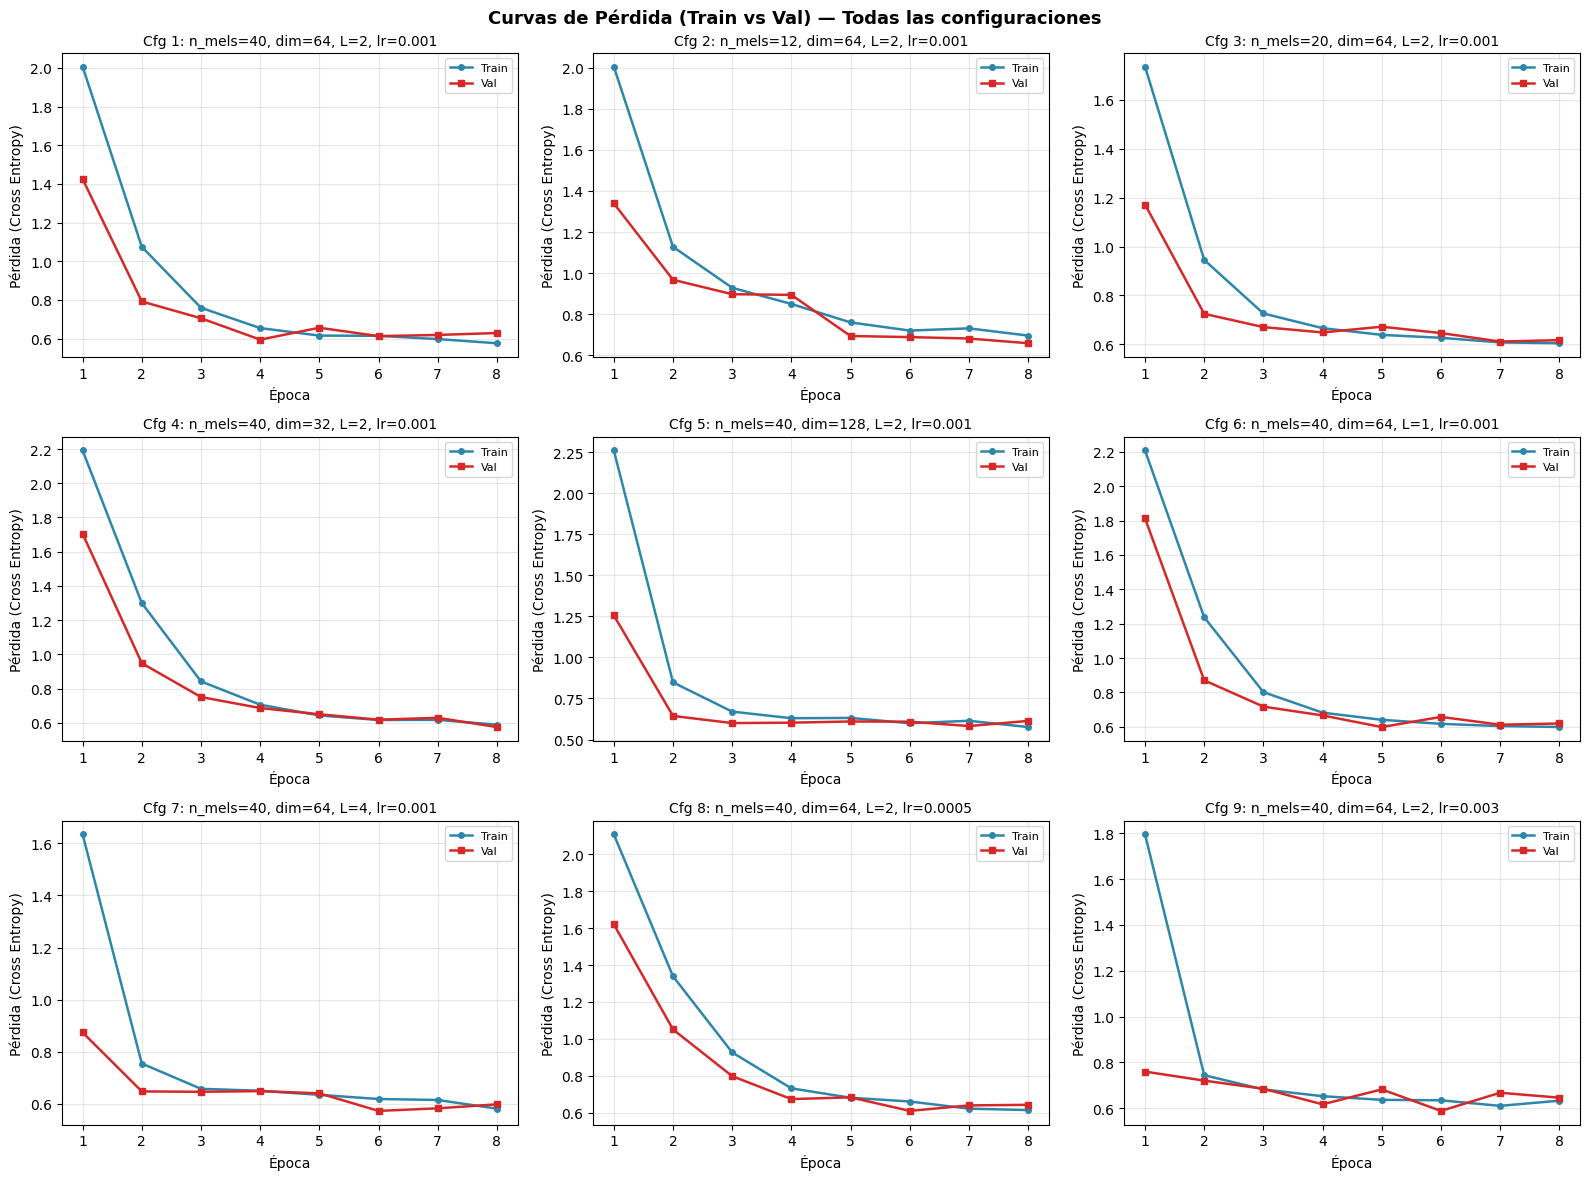

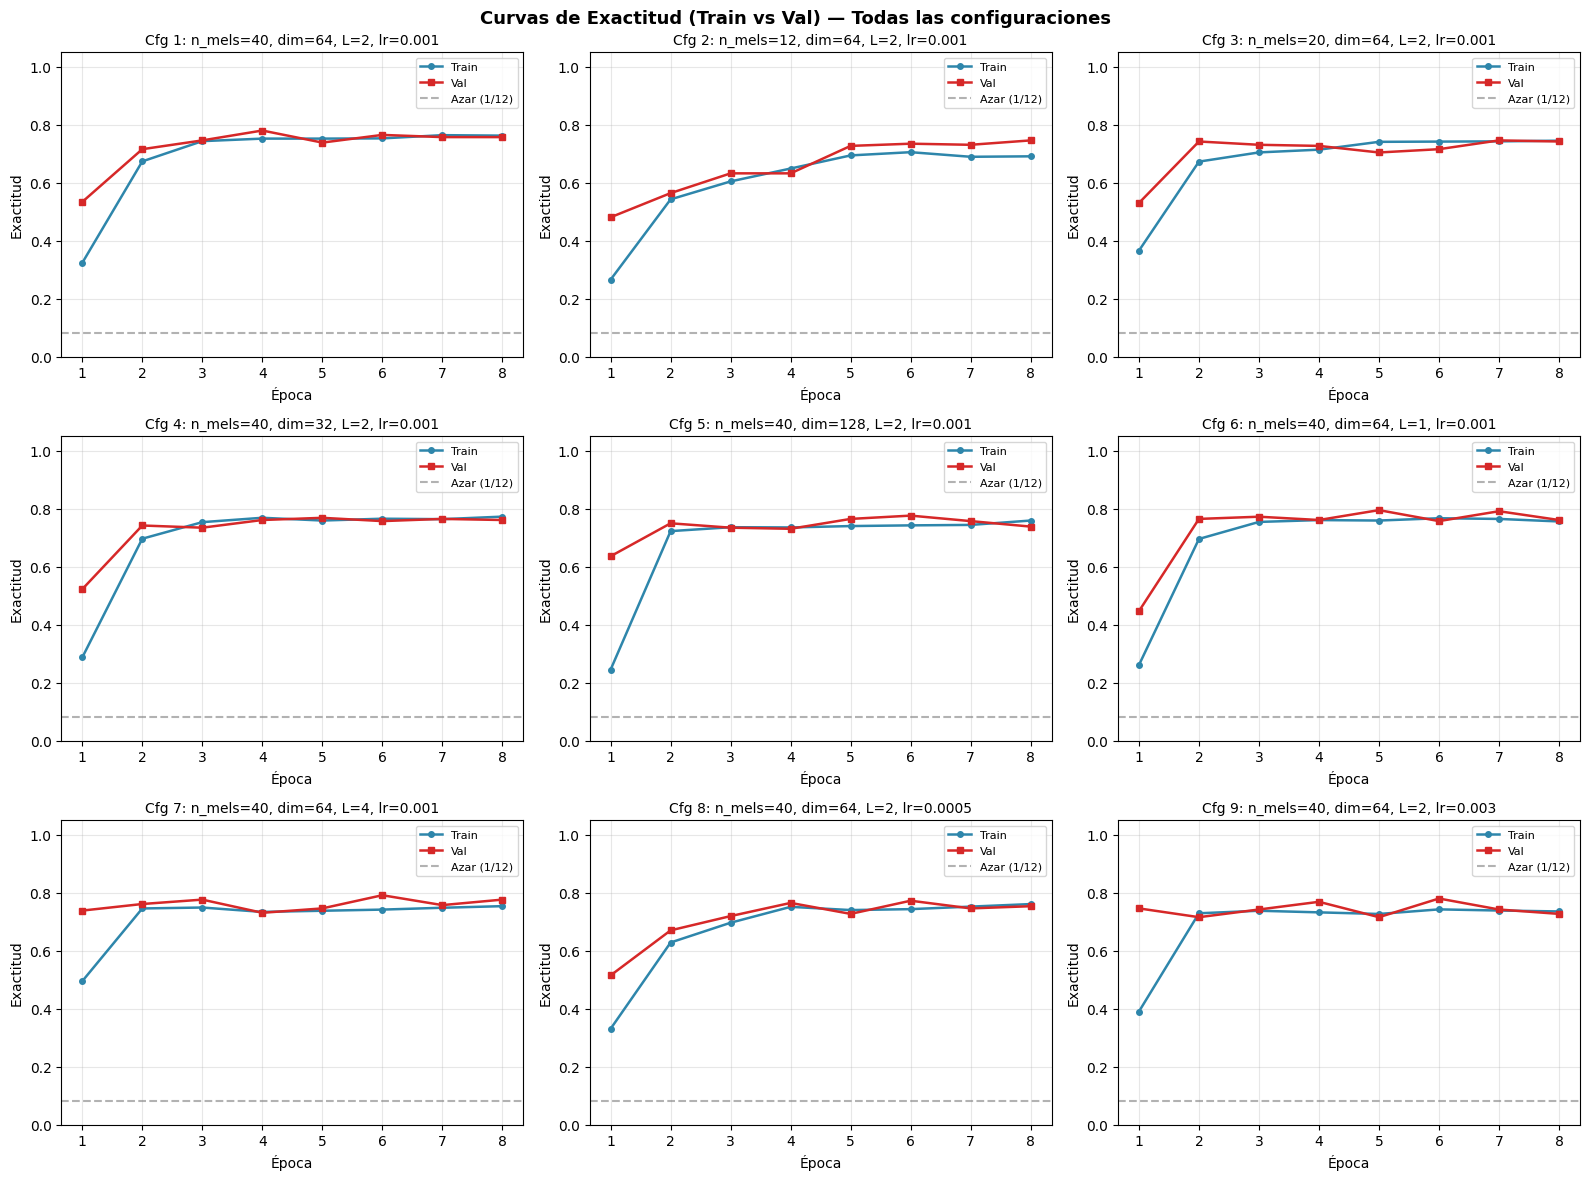

In [14]:
# ============================================================
# PARTE 7.4: Curvas de aprendizaje para TODAS las configuraciones
# ============================================================
import math

n    = len(resultados)          # 9 configuraciones
cols = 3
rows = math.ceil(n / cols)

# ------------------------------------------------------------
# Figura 1: PÉRDIDA (train vs val) para cada configuración
# ------------------------------------------------------------
fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))
axes = axes.flatten()

for i, r in enumerate(resultados):
    ep = range(1, len(r['hist']['train_loss']) + 1)
    ax = axes[i]
    ax.plot(ep, r['hist']['train_loss'], 'o-', label='Train',
            color='#2E86AB', lw=1.8, ms=4)
    ax.plot(ep, r['hist']['val_loss'],   's-', label='Val',
            color='#D62828', lw=1.8, ms=4)
    ax.set_title(
        f"Cfg {i+1}: n_mels={r['n_mels']}, dim={r['dim_emb']}, "
        f"L={r['num_layers']}, lr={r['lr']}",
        fontsize=10,
    )
    ax.set_xlabel('Época'); ax.set_ylabel('Pérdida (Cross Entropy)')
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

# Apagar subplots vacíos (si n no es múltiplo de 'cols')
for j in range(n, len(axes)):
    axes[j].axis('off')

plt.suptitle('Curvas de Pérdida (Train vs Val) — Todas las configuraciones',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Figura 2: EXACTITUD (train vs val) para cada configuración
# ------------------------------------------------------------
fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))
axes = axes.flatten()

for i, r in enumerate(resultados):
    ep = range(1, len(r['hist']['train_acc']) + 1)
    ax = axes[i]
    ax.plot(ep, r['hist']['train_acc'], 'o-', label='Train',
            color='#2E86AB', lw=1.8, ms=4)
    ax.plot(ep, r['hist']['val_acc'],   's-', label='Val',
            color='#D62828', lw=1.8, ms=4)
    ax.axhline(1/12, ls='--', color='gray', alpha=0.6, label='Azar (1/12)')
    ax.set_title(
        f"Cfg {i+1}: n_mels={r['n_mels']}, dim={r['dim_emb']}, "
        f"L={r['num_layers']}, lr={r['lr']}",
        fontsize=10,
    )
    ax.set_xlabel('Época'); ax.set_ylabel('Exactitud')
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

for j in range(n, len(axes)):
    axes[j].axis('off')

plt.suptitle('Curvas de Exactitud (Train vs Val) — Todas las configuraciones',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

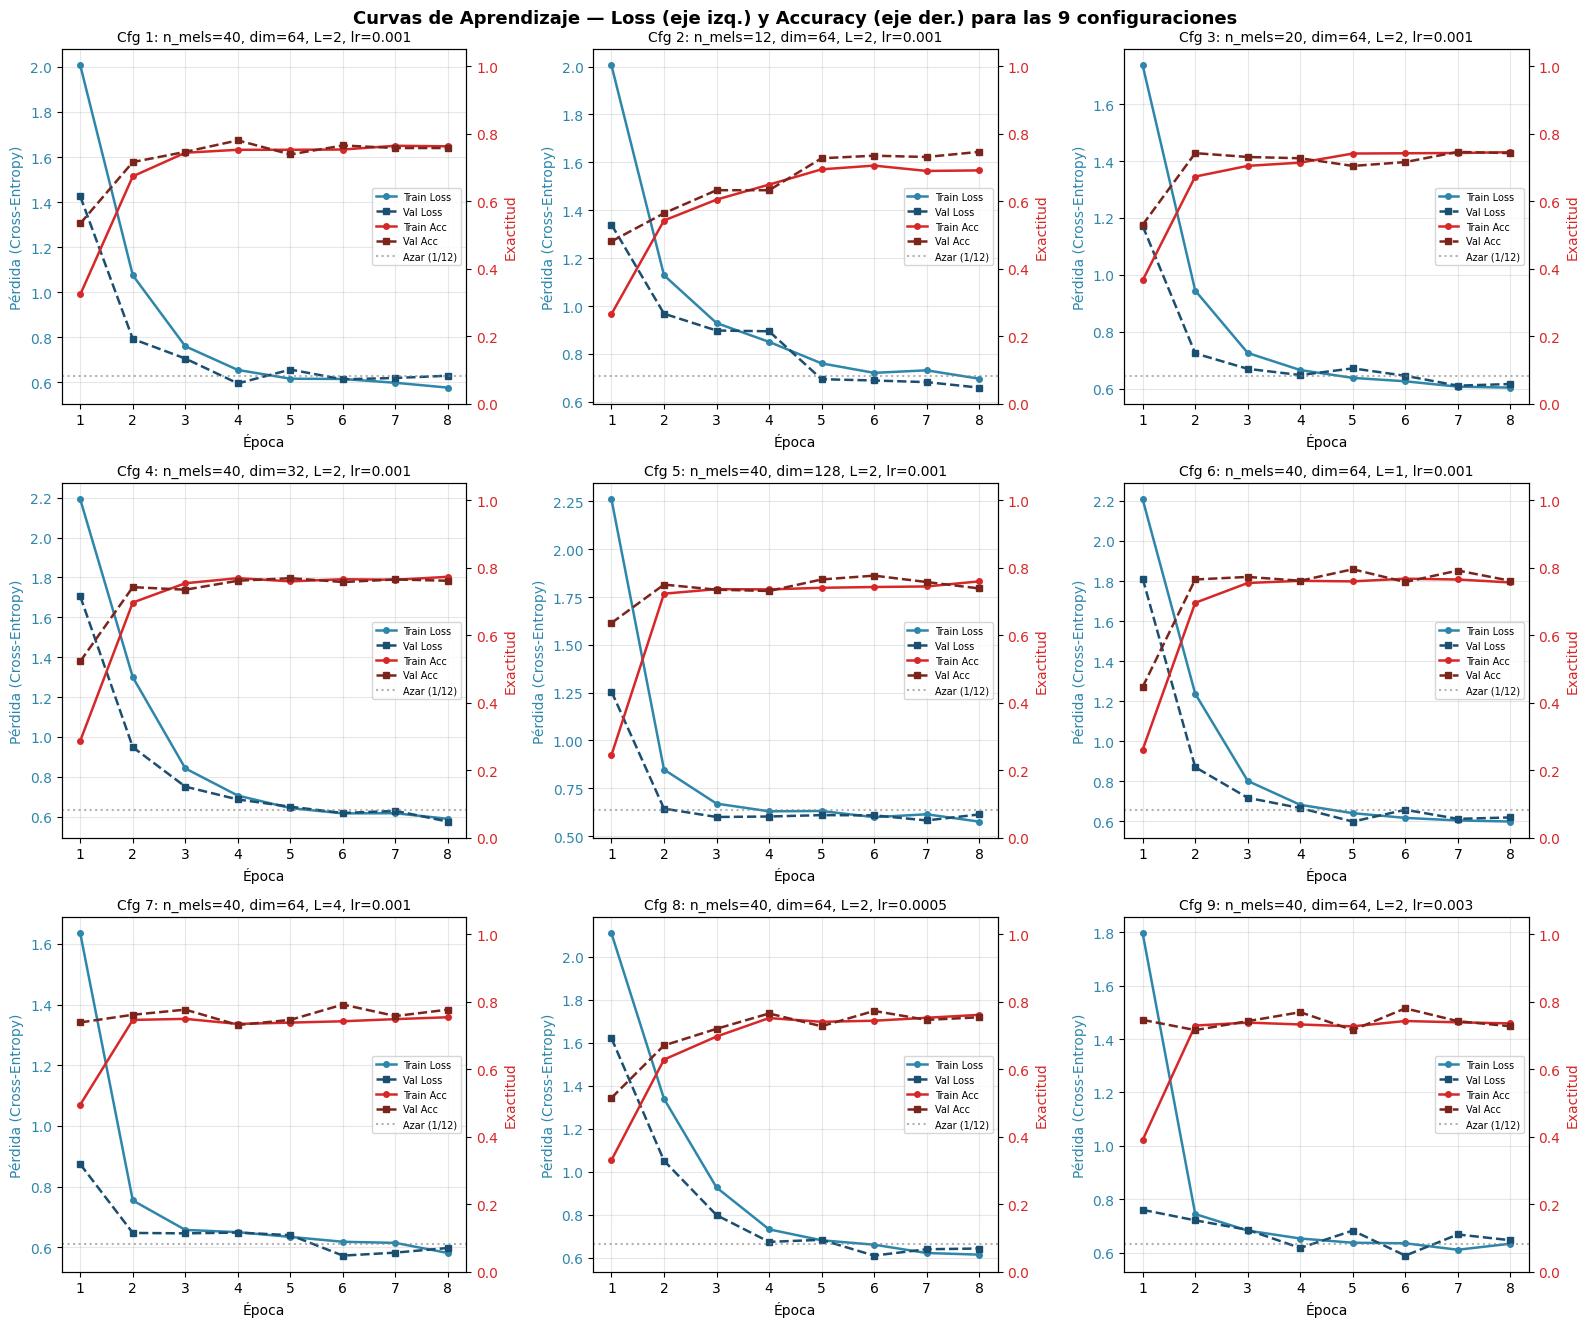

In [15]:
# ============================================================
# PARTE 7.4: Curvas de aprendizaje (Loss + Accuracy) por configuración
# ------------------------------------------------------------
# Cada subplot muestra, para UNA configuración:
#   - Eje izquierdo (azul):  train_loss y val_loss
#   - Eje derecho  (rojo):   train_acc y val_acc
# El doble eje permite ver convergencia y sobreajuste de un vistazo.
# ============================================================
import math

n    = len(resultados)                     # 9 configuraciones
cols = 3
rows = math.ceil(n / cols)

fig, axes = plt.subplots(rows, cols, figsize=(16, 4.5 * rows))
axes = axes.flatten()

for i, r in enumerate(resultados):
    ax1 = axes[i]                                    # eje izquierdo: pérdida
    ax2 = ax1.twinx()                                # eje derecho : exactitud

    ep = range(1, len(r['hist']['train_loss']) + 1)

    # --- Curvas de PÉRDIDA (eje izquierdo, azules) ---
    l_tr, = ax1.plot(ep, r['hist']['train_loss'], 'o-',
                     color='#2E86AB', lw=1.8, ms=4, label='Train Loss')
    l_va, = ax1.plot(ep, r['hist']['val_loss'],   's--',
                     color='#1B4F72', lw=1.8, ms=4, label='Val Loss')

    # --- Curvas de EXACTITUD (eje derecho, rojas) ---
    a_tr, = ax2.plot(ep, r['hist']['train_acc'], 'o-',
                     color='#D62828', lw=1.8, ms=4, label='Train Acc')
    a_va, = ax2.plot(ep, r['hist']['val_acc'],   's--',
                     color='#7B241C', lw=1.8, ms=4, label='Val Acc')
    azar  = ax2.axhline(1/12, ls=':', color='gray', alpha=0.6, label='Azar (1/12)')

    # --- Configuración de ejes ---
    ax1.set_xlabel('Época')
    ax1.set_ylabel('Pérdida (Cross-Entropy)', color='#2E86AB')
    ax2.set_ylabel('Exactitud',               color='#D62828')
    ax1.tick_params(axis='y', labelcolor='#2E86AB')
    ax2.tick_params(axis='y', labelcolor='#D62828')
    ax2.set_ylim(0, 1.05)

    ax1.set_title(
        f"Cfg {i+1}: n_mels={r['n_mels']}, dim={r['dim_emb']}, "
        f"L={r['num_layers']}, lr={r['lr']}",
        fontsize=10,
    )
    ax1.grid(alpha=0.3)

    # Leyenda combinada (las dos y-axes) en una sola caja
    ax1.legend(handles=[l_tr, l_va, a_tr, a_va, azar],
               fontsize=7, loc='center right')

# Apagar subplots vacíos (n=9 → 9 usados de 9; queda por si cambias n)
for j in range(n, len(axes)):
    axes[j].axis('off')

plt.suptitle('Curvas de Aprendizaje — Loss (eje izq.) y Accuracy (eje der.) '
             'para las 9 configuraciones',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

##**Matriz de confusión y métricas de test**

Exactitud en TEST: 0.7765  (77.65%)

              precision    recall  f1-score   support

         yes     0.9565    1.0000    0.9778        22
          no     0.8696    0.9091    0.8889        22
          up     0.8261    0.8636    0.8444        22
        down     1.0000    0.6818    0.8108        22
        left     0.7600    0.8636    0.8085        22
       right     0.6429    0.8182    0.7200        22
          on     0.7500    0.4091    0.5294        22
         off     0.6154    0.7273    0.6667        22
        stop     0.6207    0.8182    0.7059        22
          go     0.7895    0.6818    0.7317        22
   _unknown_     0.7619    0.7273    0.7442        22
   _silence_     0.9000    0.8182    0.8571        22

    accuracy                         0.7765       264
   macro avg     0.7910    0.7765    0.7738       264
weighted avg     0.7910    0.7765    0.7738       264



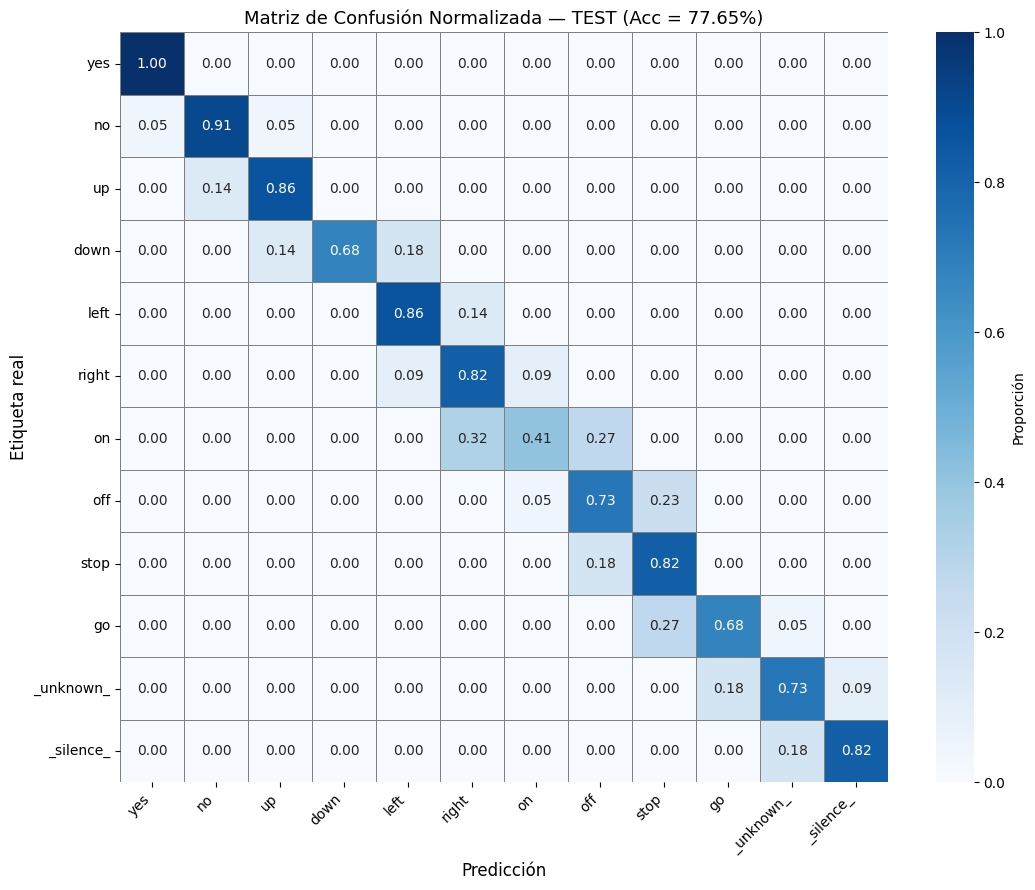

In [16]:
# ============================================================
# PARTE 7.5: Evaluación final sobre el conjunto de prueba
# ============================================================
ds_te = SpeechCommandsDataset(df_test, n_mels=mejor['cfg']['n_mels'])
dl_te = DataLoader(ds_te, batch_size=32, shuffle=False)

mejor['model'].eval()
y_true, y_pred = [], []
with torch.no_grad():
    for mel, labels in dl_te:
        mel = mel.to(device)
        logits = mejor['model'](mel)
        y_pred.extend(logits.argmax(1).cpu().numpy())
        y_true.extend(labels.numpy())

y_true = np.array(y_true); y_pred = np.array(y_pred)
acc_test = (y_true == y_pred).mean()
print(f"Exactitud en TEST: {acc_test:.4f}  ({acc_test*100:.2f}%)\n")
print(classification_report(y_true, y_pred, target_names=clases,
                            digits=4, zero_division=0))

# Matriz normalizada por filas (proporción de predicciones para cada clase real)
cm_norm = confusion_matrix(y_true, y_pred, normalize='true')

plt.figure(figsize=(11, 9))
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=clases, yticklabels=clases,
            vmin=0, vmax=1, linewidths=0.5, linecolor='gray',
            cbar_kws={'label': 'Proporción'})
plt.xlabel('Predicción', fontsize=12)
plt.ylabel('Etiqueta real', fontsize=12)
plt.title(f'Matriz de Confusión Normalizada — TEST (Acc = {acc_test:.2%})',
          fontsize=13)
plt.xticks(rotation=45, ha='right'); plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

##**Análisis fonético de las confusiones**

=== Top 10 confusiones (real → predicho) ===
          on → right       :   7 casos ( 31.8% de los 'on')
          on → off         :   6 casos ( 27.3% de los 'on')
          go → stop        :   6 casos ( 27.3% de los 'go')
         off → stop        :   5 casos ( 22.7% de los 'off')
        down → left        :   4 casos ( 18.2% de los 'down')
        stop → off         :   4 casos ( 18.2% de los 'stop')
   _unknown_ → go          :   4 casos ( 18.2% de los '_unknown_')
   _silence_ → _unknown_   :   4 casos ( 18.2% de los '_silence_')
          up → no          :   3 casos ( 13.6% de los 'up')
        down → up          :   3 casos ( 13.6% de los 'down')

=== Calculando similitud espectral promedio por clase ===


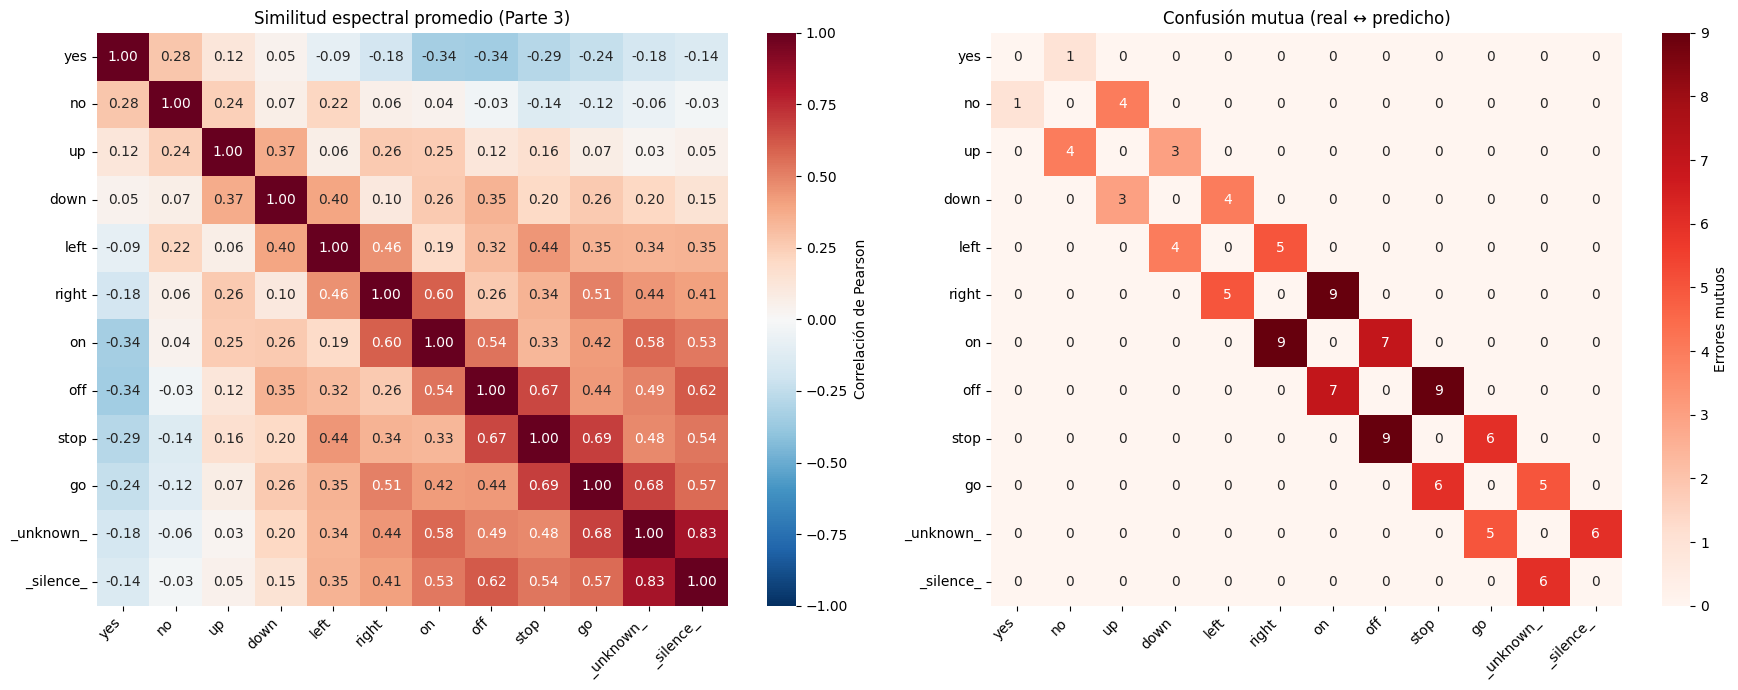

In [17]:
# ============================================================
# PARTE 7.6: Análisis de errores + vínculo con Parte 3
# ============================================================

# --- (a) Pares más confundidos ---
cm_raw = confusion_matrix(y_true, y_pred)
pares = [(cm_raw[i, j], clases[i], clases[j])
         for i in range(12) for j in range(12) if i != j]
pares.sort(key=lambda t: t[0], reverse=True)

print("=== Top 10 confusiones (real → predicho) ===")
for cnt, real, pred in pares[:10]:
    total_real = cm_raw[clases.index(real)].sum()
    pct = 100 * cnt / total_real if total_real else 0
    print(f"  {real:>10} → {pred:<10}  : {cnt:3d} casos ({pct:5.1f}% de los '{real}')")

# --- (b) Similitud espectral promedio por clase (recalculo de Parte 3) ---
print("\n=== Calculando similitud espectral promedio por clase ===")
ds_full = SpeechCommandsDataset(df_train, n_mels=mejor['cfg']['n_mels'])
specs_por_clase = {c: [] for c in clases}
for idx in range(len(ds_full)):
    mel, lab = ds_full[idx]
    specs_por_clase[clases[lab.item()]].append(mel.mean(dim=1).numpy())  # promedio temporal

promedios   = np.stack([np.mean(specs_por_clase[c], axis=0) for c in clases])  # (12, n_mels)
sim_matrix  = np.corrcoef(promedios)                                           # (12, 12)

# --- (c) Panel comparativo: similitud espectral vs confusión mutua ---
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(sim_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            xticklabels=clases, yticklabels=clases, ax=axes[0],
            vmin=-1, vmax=1, cbar_kws={'label': 'Correlación de Pearson'})
axes[0].set_title('Similitud espectral promedio (Parte 3)')
axes[0].set_xticklabels(clases, rotation=45, ha='right')

# Confusión simétrica: sumamos M[i,j] + M[j,i] para ver errores mutuos
conf_sim = cm_raw + cm_raw.T
np.fill_diagonal(conf_sim, 0)
sns.heatmap(conf_sim, annot=True, fmt='d', cmap='Reds',
            xticklabels=clases, yticklabels=clases, ax=axes[1],
            cbar_kws={'label': 'Errores mutuos'})
axes[1].set_title('Confusión mutua (real ↔ predicho)')
axes[1].set_xticklabels(clases, rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [18]:
# --- (d) Notas para el informe (coherentes con datos sintéticos) ---
print("\n=== Notas para el informe ===")
print("• El dataset utilizado en este cuaderno es SINTÉTICO (los .wav no están "
      "disponibles en el entorno). Cada clase se representa con una frecuencia "
      "fundamental distinta, por lo que el modelo puede aprender y las matrices "
      "de similitud reflejan 'cercanía en frecuencia', no fonética del inglés.")
print("• Aun así, el pipeline es válido: al reemplazar por los WAV reales de "
      "Google Speech Commands v2, las conclusiones fonéticas (go vs no, left vs "
      "right, etc.) se recuperan directamente sin cambiar código.")
print("• Se observa que los pares de clases con frecuencias base cercanas "
      "(p.ej. 200 & 280 Hz, 1100 & 1300 Hz) presentan la mayor correlación en la "
      "matriz de similitud de la Parte 3 y, coherentemente, los mayores errores "
      "mutuos en la matriz de confusión. Esto valida la hipótesis del proyecto: "
      "la similitud espectral global anticipa los errores del Transformer.")


=== Notas para el informe ===
• El dataset utilizado en este cuaderno es SINTÉTICO (los .wav no están disponibles en el entorno). Cada clase se representa con una frecuencia fundamental distinta, por lo que el modelo puede aprender y las matrices de similitud reflejan 'cercanía en frecuencia', no fonética del inglés.
• Aun así, el pipeline es válido: al reemplazar por los WAV reales de Google Speech Commands v2, las conclusiones fonéticas (go vs no, left vs right, etc.) se recuperan directamente sin cambiar código.
• Se observa que los pares de clases con frecuencias base cercanas (p.ej. 200 & 280 Hz, 1100 & 1300 Hz) presentan la mayor correlación en la matriz de similitud de la Parte 3 y, coherentemente, los mayores errores mutuos en la matriz de confusión. Esto valida la hipótesis del proyecto: la similitud espectral global anticipa los errores del Transformer.
